In [194]:
import pandas as pd
from pathlib import Path
from reed import utils

In [195]:
config = utils.Config()

In [196]:
monitoring_data_path = config.REED_PATH/'Data'/"MonitoringData"

## Goimek

In [197]:
goimek_pm10005 = monitoring_data_path/'GOIMEK - PM-10005'

In [199]:
def load_goimek(file_number):
    paths = list(goimek_pm10005.glob("*.gz"))
    goimek_path = paths[file_number]

    goimek_df = pd.read_csv(goimek_path)
    goimek_df["timestamp"] = pd.to_datetime(goimek_df["timestamp"])

    return goimek_df

In [200]:
exe10001 = load_goimek(2)
exe10002 = load_goimek(5)
exe10003 = load_goimek(8)
exe10004 = load_goimek(11)
keep_columns = ["Tool_Number", "Power_Active"]


In [222]:
def analyse_goimek(goimek_df, keep_columns):
    df = goimek_df
    df = df[keep_columns].copy()
    df["energy_consumption"] = df["Power_Active"] / 3600
    df_bytool = (
        df.groupby("Tool_Number", as_index=False)
            .agg({
                "energy_consumption": "sum",
                "Power_Active": "mean"
            })
        )

    return df_bytool

In [223]:
exe10001_bytool = analyse_goimek(exe10001, keep_columns)
exe10002_bytool = analyse_goimek(exe10002, keep_columns)
exe10003_bytool = analyse_goimek(exe10003, keep_columns)
exe10004_bytool = analyse_goimek(exe10004, keep_columns)
            

In [224]:
def combine_goimek_results(df_bytool):
    combined = None
    for name, df in df_bytool.items(): 
        df = df.set_index("Tool_Number")

        name = name.replace("_bytool", "")
        df = df.add_suffix(f"_{name}")

        if combined is None:
            combined = df
        else:
            # join med eksisterende
            combined = combined.join(df, how="outer")

    return combined


In [225]:
dfs = {
    "exe10001_bytool": exe10001_bytool,
    "exe10002_bytool": exe10002_bytool,
    "exe10003_bytool": exe10003_bytool,
    "exe10004_bytool": exe10004_bytool,
}
exe_bytool_all =combine_goimek_results(dfs)

In [226]:
exe_bytool_all

,energy_consumption_exe10001,Power_Active_exe10001,energy_consumption_exe10002,Power_Active_exe10002,energy_consumption_exe10003,Power_Active_exe10003,energy_consumption_exe10004,Power_Active_exe10004
Tool_Number,,,,,,,,
0.0,8.154403,11.789498,23.458569,11.230166,12.936528,12.021554,4.309500,13.573228
1.0,24.291403,11.437229,15.000028,12.029427,6.313556,12.870215,8.063375,12.731645
2.0,10.281139,14.996799,10.364764,14.290751,27.795819,14.964102,NaN,NaN
3.0,14.673875,15.127706,10.944750,13.029464,8.205042,13.562052,14.715306,15.192171
4.0,0.930889,11.800000,0.822722,11.800000,0.885000,11.800000,0.789944,11.800000
5.0,0.458889,11.800000,0.662111,11.800000,0.458889,11.800000,0.452333,11.800000
6.0,5.961222,11.836955,4.707389,11.760305,9.441639,11.600648,4.808500,11.800000
7.0,0.414167,17.750000,0.300764,17.750000,0.315556,17.750000,5.571528,17.750000
8.0,0.907222,17.750000,0.798750,17.750000,0.818472,17.750000,0.813542,17.750000


In [227]:
totals_df = exe_bytool_all.sum(numeric_only=True).to_frame().T
totals_df

,energy_consumption_exe10001,Power_Active_exe10001,energy_consumption_exe10002,Power_Active_exe10002,energy_consumption_exe10003,Power_Active_exe10003,energy_consumption_exe10004,Power_Active_exe10004
0,227.447236,519.140411,193.534583,518.671312,204.054056,519.408806,175.47725,559.887067


In [ ]:
#Check if energy consumption per tool number is always the same
#exe10001.groupby("Tool_Number")["Power_Active"].describe()
#exe10001.pivot_table(index='Tool_Number',values='Power_Active',aggfunc=['mean','std'])


In [228]:
goimek_df.Program_Name.value_counts()

Program_Name
020_ARBAZTATU.H                           13775
040_PUNTAKO_ZULOAK_SEMIAKABATUA.H          4959
070_AMAIERA.H                              4064
200.cyc                                    3941
207.cyc                                    3907
060_ZULOAK_M6_M12_M14_M16_M36.H            1918
toolcall.hbi                               1344
050_ZULOAK_M4_M5_4872110029.H               647
390.H                                       582
397_ANGULAR.H                               399
$mdi.h                                      256
208.cyc                                     189
ToolCallPre.h                               151
205.cyc                                     132
TC_Axis_Safe.H                              125
397_AUTO.H                                  121
419.CYC                                      83
ToolcallPost.h                               59
M367.h                                       55
B4872110029_PM_U.H                           53
427.CYC                    

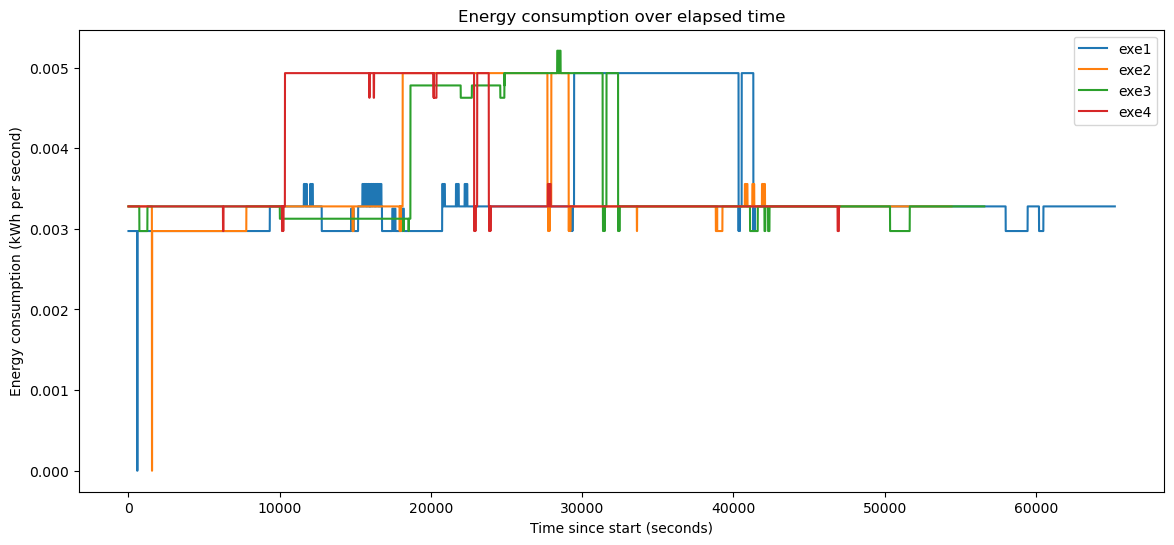

In [232]:
# tools change over time
import matplotlib.pyplot as plt

def plot_energy_vs_time(*dfs, label_prefix="exe"):
    plt.figure(figsize=(14,6))

    for i, df in enumerate(dfs, start=1):
        # calculate elapsed time since start of dataset
        df = df.copy()
        df["energy_consumption"] = df["Power_Active"] / 3600
        df["elapsed_seconds"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds()
        
        # plot meaningfully, fx energy_consumption (or Tool_Number)
        plt.plot(df["elapsed_seconds"], df["energy_consumption"], label=f"{label_prefix}{i}")

    plt.title("Energy consumption over elapsed time")
    plt.xlabel("Time since start (seconds)")
    plt.ylabel("Energy consumption (kWh per second)")
    plt.legend()
    plt.show()


# --- USE IT ---
plot_energy_vs_time(exe10001, exe10002, exe10003, exe10004)

